# DS 2002 Midterm - Walmart Hurricane Project

Henna Panjshiri, Kaavya Indrayan, Amran (Dina) Belete, Maya Yonathan

In [1]:
from pathlib import Path
from IPython.display import display
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests, time, os, re

# Cloning the Github repo
from pathlib import Path

if not Path('/content/walmart-hurricane-project').exists():
    !git clone https://github.com/hpanjshiri/walmart-hurricane-project.git

%cd /content/walmart-hurricane-project

# Loading the data directiory directly from repo
DATA_DIR = next((p for p in [Path('data'), Path('.'), Path('/content/walmart-hurricane-project/data'), Path('/mnt/data')] if (p / 'walmart_transactions.csv').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Data not found. Clone the repo or place all CSVs and inventory_and_sales.db in data/.')
print('Using input directory:', DATA_DIR.resolve())
# Later unctions use find_data() for reference

Cloning into 'walmart-hurricane-project'...
remote: Enumerating objects: 72, done.
remote: Counting objects: 100% (72/72), done.
remote: Compressing objects: 100% (66/66), done.
remote: Total 72 (delta 34), reused 19 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (72/72), 1.18 MiB | 6.17 MiB/s, done.
Resolving deltas: 100% (34/34), done.
/content/walmart-hurricane-project
Using input directory: /content/walmart-hurricane-project/data


## Data Loading

To start, we load the raw transaction, store location, product catalog, and distrubution center data files directly from our GitHub repository. We also load the SQLite sales and inventory databases separately. We are keeping the raw data unchanged to allow us to compare the original records to the cleaned data and verify that our changes don't mistakenly transform our results.

In [2]:
def find_data(filename, folders=('data', '../data', '../../data', '/content/walmart-hurricane-project/data', '/content/data', '/kaggle/input', '/content')):
  for folder in folders:
    if os.path.exists(os.path.join(folder, filename)):
      return os.path.join(folder, filename)
  raise FileNotFoundError(f'{filename} not found. Put data files in repo in the data/ folder.')

DECISIONS = [] # Storing every cleaning decision made
COUNTS = [] # Rows before then after each step

def log(step, decision, rows_affected, dropped=False):
  # dropped = True means those rows were removed and validation will use it to check the row math
  DECISIONS.append({'step': step, 'decision': decision, 'rows': int(rows_affected), 'dropped': dropped})
  print(f'[{step}] {decision} ({int(rows_affected)} row(s))')

def run_step(name, fn, df, *args):
  # Used to run a cleaning function and record the row count before then after
  before = len(df)
  out = fn(df, *args)
  COUNTS.append({'step': name, 'rows_before': before, 'rows_after': len(out)})
  return out

def show_log():
  return pd.DataFrame(DECISIONS)

def show_counts():
  return pd.DataFrame(COUNTS)

pd.set_option('display.max_colwidth', 90)
print('pandas', pd.__version__)

pandas 2.2.3


In [3]:
def extract():
  tx = pd.read_csv(find_data('walmart_transactions.csv'))
  stores = pd.read_csv(find_data('store_locations.csv'))
  catalog = pd.read_csv(find_data('product_catalog.csv'))
  dcs = pd.read_csv(find_data('distribution_centers.csv'))
  print(f'transactions: {len(tx):,} rows | stores: {len(stores)} | catalog: {len(catalog)} | distribution centers: {len(dcs)}')
  return tx, stores, catalog, dcs

tx_raw, stores_raw, catalog_raw, dcs_raw = extract()
tx_raw.head()

transactions: 25,562 rows | stores: 14 | catalog: 45 | distribution centers: 5


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


In [4]:
# Raw profile to see the uncleaned version later
print(tx_raw.dtypes, '\n')
print('nulls per column (pandas default null detection):')
print(tx_raw.isnull().sum(), '\n')
print('exact duplicate rows:', tx_raw.duplicated().sum())
print('transaction_id repeats:', tx_raw['transaction_id'].duplicated().sum())

# Hidden missing values as strings because pandas doesn't treat str types as null
for col in tx_raw.select_dtypes(include=['object', 'string']).columns:
  s = tx_raw[col].dropna().astype(str).str.strip().str.lower()
  hits = s[s.isin(['', 'none', 'null', 'n/a', 'na', 'nan', '-', '--', '?', 'unknown', 'missing', 'tbd'])]
  if len(hits):
      print(f'hidden placeholders in {col}:', hits.value_counts().to_dict())


transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object 

nulls per column (pandas default null detection):
transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64 

exact duplicate rows: 30
transaction_id repeats: 30


**Missing values:** Placeholder strings like "N/A" or empty strings we standardize into actual missing values. We keep records with missing prices or timestamps because they may still have useful information, but don't include them in analyses requiring those fields. Records without a viable SKU or quantity are removed because we can't rely on them for product-level demand calculations.

In [5]:
PLACEHOLDERS = {'', 'none', 'null', 'n/a', 'na', 'nan', '-', '--', '?', 'unknown', 'missing', 'tbd'}

def standardize_missing(df):
  # Turn placeholder strings into real NaN, trim spaces
  out = df.copy()
  for col in out.select_dtypes(include='object').columns:
    stripped = out[col].astype('string').str.strip()
    is_placeholder = stripped.str.lower().isin(PLACEHOLDERS) & out[col].notna()
    out[col] = stripped.where(~is_placeholder, other=pd.NA).astype(object)
    out[col] = out[col].where(out[col].notna(), np.nan)
    if is_placeholder.sum():
      log('missing_placeholders', f'{col}: {int(is_placeholder.sum())} placeholder strings converted to NaN',
        is_placeholder.sum())
  log('whitespace', 'checked all text cols for extra spaces', len(out))
  return out

def handle_required_nulls(df):
  # Dropping rows with no sku because they can't be tied to a product, other nulls kept and handled based on the step that owns that col
  out = df[df['sku'].notna()].copy()
  log('sku_missing', 'dropped rows with no sku (no tie to a product)', len(df) - len(out), dropped=True)
  for col, why in [('timestamp', 'kept; the sale is real, just cant sit on a day'),
                   ('unit_price', 'kept as NaN; we cannot make up a price. Revenue questions will skip these rows'),
                   ('store_id', 'kept as NaN; counts toward totals')]:
    if col in out.columns:
      log(f'null_{col}', f'{col} nulls {why}', out[col].isna().sum())
  return out

**Duplicates, prices, and quantities:** Exact duplicate transactions are removed to avoid double counting, while retaining records that share a transaction ID but have different information. Prices are converted into numeric values after removing formatting characters like "$" or ".". Negative quantities are flagged to potentially be returns or adjustments rather than deleted entirely, so we keep the original transaction information while not including returns from our positive-demand analyses.

In [6]:
def drop_duplicates(df):
  out = df.drop_duplicates().copy()
  log('duplicates', 'dropped exact duplicate rows (kept first copy)', len(df) - len(out), dropped=True)
  # Reporting same id with different contents
  repeated_ids = out['transaction_id'].duplicated().sum()
  print('rows sharing a transaction_id after dedupe:', repeated_ids)
  log('duplicate_ids', 'rows sharing a transaction_id with diff contents (only reported)', repeated_ids)
  return out

In [7]:
def fix_prices(df):
  out = df.copy()
  cleaned = out['unit_price'].astype('string').str.replace(r'[$,\s]', '', regex=True)
  out['unit_price'] = pd.to_numeric(cleaned, errors='coerce').astype(float)
  new_nan = out['unit_price'].isna().sum() - df['unit_price'].isna().sum()
  log('prices', 'stripped $, commas, spaces and converted unit_price to float', len(out))
  log('prices_unparseable', 'values that could not become numbers', max(new_nan, 0))
  log('prices_nonpositive', 'unit_price <= 0 (only reported)', (out['unit_price'] <= 0).sum())
  return out

In [8]:
def fix_quantity(df):
  out = df.copy()
  out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
  # Drop quantity if none, cant add to total
  n_missing = out['quantity'].isna().sum()
  out = out[out['quantity'].notna()].copy()
  log('quantity_missing', 'dropped rows with no / unreadable quantity', n_missing, dropped=True)
  # Flag negatives but keep them
  out['quantity'] = out['quantity'].astype(int)
  out['is_return'] = out['quantity'] < 0
  log(
    'quantity_negative',
    'kept negative quantities as likely returns/adjustments; flagged is_return=True',
    out['is_return'].sum()
  )
  log('quantity_zero', 'quantity 0 (kept, reported only)', (out['quantity'] == 0).sum())
  return out

**Store IDs and timestamps:** We standardized store identifiers into a consistent format so transactions can be matched to store locations. Inconsistent state labels and parse mixed timestamp formats are normalized into the same datetime type. Transactions without valid timestamps are retained n the cleaned dataset, but not included in daily trend analyses, since assigning them a date could mess with the pre-hurricane surge

In [9]:
def norm_store_id(value):
  # FL239, fl-239, 'FL 239', FL_239 -> FL-239 (3 digits, matches store_locations)
  if pd.isna(value):
      return np.nan
  key = re.sub(r'[^A-Z0-9]', '', str(value).upper())
  m = re.match(r'^([A-Z]+)0*(\d+)$', key)
  return f'{m.group(1)}-{int(m.group(2)):03d}' if m else key

def fix_store_ids(df, stores):
  out = df.copy()
  before = out['store_id'].nunique()
  out['store_id'] = out['store_id'].apply(norm_store_id)
  log('store_id', f'normalized store ids to XX-### ({before} variants -> {out["store_id"].nunique()})', len(out))
  valid = set(stores['store_id'])
  unmatched = out[out['store_id'].notna() & ~out['store_id'].isin(valid)]['store_id']
  if len(unmatched):
      print('   WARNING store ids not in store_locations:', sorted(unmatched.unique()))
  log('store_id_unmatched', 'rows whose store_id is not in store_locations (kept, reported)', len(unmatched))
  return out

In [10]:
def clean_stores(stores):
  """store_locations has the same store written two ways (FL239, FL_287), state spelled 3 ways, and one store with no coordinates."""
  out = stores.copy()
  n0 = len(out)
  out['store_id'] = out['store_id'].apply(norm_store_id)
  out['state'] = out['state'].astype(str).str.strip().replace({'Florida': 'FL', 'Fla.': 'FL'})
  for col in ['store_name', 'city', 'region']:
      out[col] = out[col].astype('string').str.strip()
  out = out.drop_duplicates().reset_index(drop=True)
  log('stores_duplicates', f'store_locations: same store written two ways, kept one ({n0} rows -> {len(out)})', n0 - len(out))
  log('stores_state', 'state spellings (Florida / Fla. / FL) standardized to FL', len(out))
  missing_xy = out[out['latitude'].isna() | out['longitude'].isna()]['store_id'].tolist()
  # Decision: not inventing coordinates, helping with Q4
  log('stores_no_coordinates', f'stores with no lat/lon (left blank, reported): {missing_xy}', len(missing_xy))
  assert out['store_id'].is_unique, 'store ids still repeat in store_locations'
  return out

def clean_dcs(dcs):
  out = dcs.copy()
  raw = out['surge_capacity'].astype(str)
  out['surge_capacity_approx'] = raw.str.contains('~')
  out['surge_capacity'] = pd.to_numeric(raw.str.replace(r'[^0-9.]', '', regex=True), errors='coerce')
  log('dc_surge_capacity', 'surge_capacity had "~" in front of a number; stripped it, flagged surge_capacity_approx', out['surge_capacity_approx'].sum())
  log('dc_missing_cost', 'cost_per_shipment missing (left as NaN, not invented)', out['cost_per_shipment'].isna().sum())
  return out

In [11]:
def fix_timestamps(df):
  out = df.copy()
  parsed = pd.to_datetime(out['timestamp'], format='mixed', errors='coerce')
  unparseable = (out['timestamp'].notna() & parsed.isna()).sum()
  out['timestamp'] = parsed
  out['date'] = out['timestamp'].dt.normalize()
  # Kept rows with no timestamp
  log('timestamps', 'parsed mixed formats; kept rows with no timestamp (date = NaT)', out['timestamp'].isna().sum())
  log('timestamps_unparseable', 'text timestamps that would not parse (now NaT)', unparseable)
  in_range = out['date'].between('2024-09-01', '2024-09-30') | out['date'].isna()
  log('timestamps_out_of_range', 'dates outside Sept 2024 (check day/month swap)', (~in_range).sum())
  print('date range:', out['date'].min().date(), 'to', out['date'].max().date())
  return out

**Category and SKU standardization:** We found 37 category variations that represented only 10 categories, so we created a mapping to combine inconsistent labels. We also map the 45 original SKU identifiers to 20 canonical products while keeping the original SKU values in tact. This allows the same product level to not be counted as separate items and makes category-level and product-level comparisons more accurate.

In [12]:
CATEGORY_MAP = {
  'breakfast': 'Breakfast', 'breakfastfoods': 'Breakfast',
  'emergency': 'Emergency', 'emergencysupplies': 'Emergency',
  'entertainment': 'Entertainment', 'gamesentertainment': 'Entertainment',
  'grocery': 'Grocery', 'groceries': 'Grocery',
  'household': 'Household', 'householdessentials': 'Household',
  'electronics': 'Electronics',
  'health': 'Health', 'healthwellness': 'Health',
  'baby': 'Baby', 'babyproducts': 'Baby',
  'alcohol': 'Alcohol', 'alcoholicbeverages': 'Alcohol', 'alcoholic': 'Alcohol',
  'snacks': 'Snacks', 'snack': 'Snacks',
}

def fix_categories(df):
  """37 spellings -> 10 categories. Lowercase + letters only, then look up in CATEGORY_MAP."""
  out = df.copy()
  before = out['category'].nunique()
  key = out['category'].astype(str).str.lower().str.replace(r'[^a-z]', '', regex=True)
  mapped = key.map(CATEGORY_MAP)
  leftover = sorted(out.loc[mapped.isna(), 'category'].dropna().unique())
  if leftover:
      print('   REVIEW these categories are not in CATEGORY_MAP (kept, title-cased):', leftover)
  out['category'] = mapped.fillna(out['category'].astype(str).str.strip().str.title())
  log('category', f'normalized category labels ({before} variants -> {out["category"].nunique()})', len(out))
  conflicts = (out.groupby('sku')['category'].nunique() > 1).sum()
  log('category_conflicts', 'skus that still have more than one category (should be 0)', conflicts)
  return out

In [13]:
SKU_MAP = {
  # Strawberry Pop-Tarts
  'PT-12': ('POPTART-STRAWBERRY', 'Strawberry Pop-Tarts'),
  'SKU#459812': ('POPTART-STRAWBERRY', 'Strawberry Pop-Tarts'),
  'POPTART-STRAW': ('POPTART-STRAWBERRY', 'Strawberry Pop-Tarts'),
  'PT_STRAWBERRY': ('POPTART-STRAWBERRY', 'Strawberry Pop-Tarts'),

  # Bottled Water
  'WTR-24': ('WATER-24PK', 'Bottled Water 24-Pack'),
  'WATER24PK': ('WATER-24PK', 'Bottled Water 24-Pack'),
  'WTR_24PK': ('WATER-24PK', 'Bottled Water 24-Pack'),

  # AA Batteries
  'BATT-100': ('BATTERY-AA4', 'AA Batteries 4-Pack'),
  'BAT-AA4': ('BATTERY-AA4', 'AA Batteries 4-Pack'),
  'BATT_AA_4PK': ('BATTERY-AA4', 'AA Batteries 4-Pack'),

  # Flashlights
  'FLASH-01': ('FLASHLIGHT-LED', 'LED Flashlight'),
  'LED-FLASH': ('FLASHLIGHT-LED', 'LED Flashlight'),

  # Light Beer
  'BEER-24': ('LIGHTBEER-24', 'Light Beer 24-Pack'),
  'LTBEER24': ('LIGHTBEER-24', 'Light Beer 24-Pack'),

  # Monopoly
  'BG-MONO': ('MONOPOLY', 'Monopoly Board Game'),
   'MONOPOLY-01': ('MONOPOLY', 'Monopoly Board Game'),
  'GAME-MONO': ('MONOPOLY', 'Monopoly Board Game'),

  # Playing Cards
  'CARDS-01': ('PLAYING-CARDS', 'Playing Cards'),
  'PLAYCARD-STD': ('PLAYING-CARDS', 'Playing Cards'),

  # Streaming Device
  'STREAM-01': ('STREAMING-DEVICE', 'Streaming Device'),
  'ROKU-STD': ('STREAMING-DEVICE', 'Streaming Device'),

  # Canned Soup
  'SOUP-CAN': ('CANNED-SOUP', 'Canned Soup'),
  'CNSOUP-01': ('CANNED-SOUP', 'Canned Soup'),

  # White Bread
  'BREAD-WH': ('WHITE-BREAD', 'White Bread'),
  'WHITEBREAD': ('WHITE-BREAD', 'White Bread'),

  # Peanut Butter
  'PB-16': ('PEANUT-BUTTER', 'Peanut Butter'),
  'PNUTBTR-16': ('PEANUT-BUTTER', 'Peanut Butter'),

  # Emergency Candles
  'CNDL-EM': ('EMERGENCY-CANDLES', 'Emergency Candles'),
  'CANDLE-EMRG': ('EMERGENCY-CANDLES', 'Emergency Candles'),

  # First Aid Kit
  'FAID-01': ('FIRST-AID-KIT', 'First Aid Kit'),
  'FIRSTAID-KIT': ('FIRST-AID-KIT', 'First Aid Kit'),

  # Portable Charger
  'CHRG-PORT': ('PORTABLE-CHARGER', 'Portable Phone Charger'),
  'PORTCHARGER': ('PORTABLE-CHARGER', 'Portable Phone Charger'),

  # Chips
  'CHIPS-VP': ('CHIPS-VARIETY', 'Chips Variety Pack'),
  'CHIPVARIETY': ('CHIPS-VARIETY', 'Chips Variety Pack'),

  # Paper Towels
  'PTOWEL-6': ('PAPER-TOWELS', 'Paper Towels'),
  'PAPERTOWEL6': ('PAPER-TOWELS', 'Paper Towels'),

  # Toilet Paper
  'TP-12': ('TOILET-PAPER-12', 'Toilet Paper 12-Roll'),
  'TOILETPAPER12': ('TOILET-PAPER-12', 'Toilet Paper 12-Roll'),

  # Diapers
  'DIAP-S3': ('DIAPERS-SIZE3', 'Baby Diapers Size 3'),
  'DIAPERS-3': ('DIAPERS-SIZE3', 'Baby Diapers Size 3'),

  # Baby Formula
  'BFORM-01': ('BABY-FORMULA', 'Baby Formula'),
  'BABYFORMULA': ('BABY-FORMULA', 'Baby Formula'),

  # Heavy Duty Tarp
  'TARP-HD': ('HEAVY-DUTY-TARP', 'Heavy Duty Tarp'),
  'HDTARP-01': ('HEAVY-DUTY-TARP', 'Heavy Duty Tarp'),
}

In [14]:
def fix_skus_and_products(df):
    out = df.copy()

    # Keep original sku/product_name for Q2
    out['canonical_sku'] = out['sku'].map(
        lambda x: SKU_MAP.get(x, (x, None))[0]
    )

    out['canonical_product_name'] = out.apply(
        lambda row: SKU_MAP.get(
            row['sku'],
            (row['sku'], str(row['product_name']).strip())
        )[1],
        axis=1
    )

    unmapped = sorted(set(out['sku'].dropna()) - set(SKU_MAP.keys()))

    log(
        'sku_consolidation',
        f'consolidated SKU variants into canonical products; {len(unmapped)} SKUs not explicitly mapped',
        len(out)
    )

    if unmapped:
        print('SKUs not explicitly mapped:', unmapped)

    print(
        'unique SKUs:',
        out['sku'].nunique(),
        '-> canonical products:',
        out['canonical_sku'].nunique()
    )

    return out

In [15]:
def clean_catalog(catalog):
    out = catalog.copy()

    # Standardize missing-value representations and whitespace
    for col in out.select_dtypes(include='object').columns:
        stripped = out[col].astype('string').str.strip()
        is_placeholder = stripped.str.lower().isin(PLACEHOLDERS) & out[col].notna()
        out[col] = stripped.where(~is_placeholder, other=pd.NA)

    # Add the same canonical identifiers used in transactions
    out['canonical_sku'] = out['sku'].map(
        lambda x: SKU_MAP.get(x, (x, None))[0]
    )

    out['canonical_product_name'] = out.apply(
        lambda row: SKU_MAP.get(
            row['sku'],
            (row['sku'], str(row['product_name']).strip())
        )[1],
        axis=1
    )

    # Standardize catalog categories using the same rules as transactions
    key = (
        out['category']
        .astype(str)
        .str.lower()
        .str.replace(r'[^a-z]', '', regex=True)
    )

    mapped = key.map(CATEGORY_MAP)
    out['category'] = mapped.fillna(
        out['category'].astype(str).str.strip().str.title()
    )

    log(
        'catalog_sku_consolidation',
        f'product catalog: {out["sku"].nunique()} SKUs mapped to {out["canonical_sku"].nunique()} canonical products',
        len(out)
    )

    return out

**Pipeline validation:** After cleaning, we check duplicate records have been removed, store identifiers are consistent, category and SKU mappings are complete, and row counts are accurate to documented removals. We also maintain a decision log throughout to record which transformations change the data and why. These checks help differentiate cleaning decisions from accidental data loss.

In [16]:
def validate(clean, raw_rows, stores, catalog):
  dropped = sum(d['rows'] for d in DECISIONS if d['dropped'])
  assert clean.duplicated().sum() == 0, 'exact duplicates survived'
  assert len(clean) == raw_rows - dropped, f'row count {len(clean)} != {raw_rows} - {dropped} from the log'
  assert clean['unit_price'].dtype == float, 'unit_price is not numeric'
  assert clean['sku'].notna().all(), 'sku has nulls'
  assert pd.api.types.is_integer_dtype(clean['quantity']), 'quantity is not an integer'
  assert clean['store_id'].dropna().str.match(r'^[A-Z]+-\d{3}$').all(), 'store_id has a bad format'
  assert set(clean['store_id'].dropna()) <= set(stores['store_id']), 'a transaction store is missing from store_locations'
  assert pd.api.types.is_datetime64_any_dtype(clean['date']), 'date is not datetime'
  assert clean['category'].notna().all() and clean['category'].nunique() == 10, 'categories did not collapse to 10'
  assert clean.groupby('sku')['category'].nunique().max() == 1, 'a sku has more than one category'
  assert 'canonical_sku' in clean.columns
  assert 'canonical_product_name' in clean.columns

  poptart_skus = [
      'PT-12',
      'SKU#459812',
      'POPTART-STRAW',
      'PT_STRAWBERRY'
  ]

  poptarts = clean[clean['sku'].isin(poptart_skus)]

  assert poptarts['canonical_sku'].nunique() == 1, \
      'Pop-Tart SKU variants did not consolidate to one product'

  assert poptarts['canonical_product_name'].nunique() == 1, \
      'Pop-Tart product names did not consolidate to one product name'

  # SKUs should exist in the supplied product catalog
  assert set(clean['sku']) <= set(catalog['sku']), \
      'transaction contains SKU not found in product catalog'

  for col in clean.select_dtypes(include=['object', 'string']).columns:
      left = clean[col].dropna().astype(str).str.strip().str.lower().isin(PLACEHOLDERS).sum()
      assert left == 0, f'{col} still has placeholder strings'
  print('all validation checks passed')

In [17]:
def run_pipeline(save=True):
  DECISIONS.clear(); COUNTS.clear()

  out_dir = 'cleaned_data'
  os.makedirs(out_dir, exist_ok=True)

  tx, stores_raw_, catalog_raw_, dcs = extract()
  raw_rows = len(tx)

  stores = clean_stores(stores_raw_)
  catalog = clean_catalog(catalog_raw_)
  dcs_clean = clean_dcs(dcs)

  df = run_step('standardize_missing', standardize_missing, tx)
  df = run_step('handle_required_nulls', handle_required_nulls, df)
  df = run_step('drop_duplicates', drop_duplicates, df)
  df = run_step('fix_prices', fix_prices, df)
  df = run_step('fix_quantity', fix_quantity, df)
  df = run_step('fix_store_ids', fix_store_ids, df, stores)
  df = run_step('fix_timestamps', fix_timestamps, df)
  df = run_step('fix_categories', fix_categories, df)
  df = run_step('fix_skus_and_products', fix_skus_and_products, df)

  validate(df, raw_rows, stores, catalog)
  if save:
    df.to_csv(os.path.join(out_dir, 'clean_transactions.csv'), index=False)
    stores.to_csv(os.path.join(out_dir, 'clean_stores.csv'), index=False)
    catalog.to_csv(os.path.join(out_dir, 'clean_product_catalog.csv'), index=False)
    dcs_clean.to_csv(os.path.join(out_dir, 'clean_distribution_centers.csv'), index=False)
    print(
      'saved clean_transactions.csv, clean_stores.csv, '
      'clean_product_catalog.csv, clean_distribution_centers.csv to',
      out_dir
    )
  return df, stores, catalog, dcs_clean

clean, stores_clean, catalog_clean, dcs_clean = run_pipeline()
print(f'\n{len(tx_raw):,} raw rows -> {len(clean):,} clean rows ({len(tx_raw) - len(clean)} removed)')
show_counts()

transactions: 25,562 rows | stores: 14 | catalog: 45 | distribution centers: 5
[stores_duplicates] store_locations: same store written two ways, kept one (14 rows -> 12) (2 row(s))
[stores_state] state spellings (Florida / Fla. / FL) standardized to FL (12 row(s))
[stores_no_coordinates] stores with no lat/lon (left blank, reported): ['FL-619'] (1 row(s))
[catalog_sku_consolidation] product catalog: 45 SKUs mapped to 20 canonical products (45 row(s))
[dc_surge_capacity] surge_capacity had "~" in front of a number; stripped it, flagged surge_capacity_approx (1 row(s))
[dc_missing_cost] cost_per_shipment missing (left as NaN, not invented) (1 row(s))
[whitespace] checked all text cols for extra spaces (25562 row(s))
[sku_missing] dropped rows with no sku (no tie to a product) (0 row(s))
[null_timestamp] timestamp nulls kept; the sale is real, just cant sit on a day (886 row(s))
[null_unit_price] unit_price nulls kept as NaN; we cannot make up a price. Revenue questions will skip these ro

,step,rows_before,rows_after
0,standardize_missing,25562,25562
1,handle_required_nulls,25562,25562
2,drop_duplicates,25562,25532
3,fix_prices,25532,25532
4,fix_quantity,25532,25532
5,fix_store_ids,25532,25532
6,fix_timestamps,25532,25532
7,fix_categories,25532,25532
8,fix_skus_and_products,25532,25532


**Cleaning results:** The dataset for transactions decreased from 25,562 to 25,532 rows after removing 30 exact duplicates. Additionally, we kept 884 transactions with missing timestamps and flagged 130 negative quantity records. The final dataset has 12 standardized store, 10 product categories, and 20 canonical products. These cleaned datasets serve as the shared input for Q1-Q5.

In [18]:
show_log().drop(columns="dropped")

,step,decision,rows
0,stores_duplicates,"store_locations: same store written two ways, kept one (14 rows -> 12)",2
1,stores_state,state spellings (Florida / Fla. / FL) standardized to FL,12
2,stores_no_coordinates,"stores with no lat/lon (left blank, reported): ['FL-619']",1
3,catalog_sku_consolidation,product catalog: 45 SKUs mapped to 20 canonical products,45
4,dc_surge_capacity,"surge_capacity had ""~"" in front of a number; stripped it, flagged surge_capacity_approx",1
5,dc_missing_cost,"cost_per_shipment missing (left as NaN, not invented)",1
6,whitespace,checked all text cols for extra spaces,25562
7,sku_missing,dropped rows with no sku (no tie to a product),0
8,null_timestamp,"timestamp nulls kept; the sale is real, just cant sit on a day",886
9,null_unit_price,unit_price nulls kept as NaN; we cannot make up a price. Revenue questions will skip t...,0


In [19]:
display(show_counts())
print('Rows:',len(tx_raw),'→',len(clean))
print('Unique categories:',clean['category'].nunique(),'| raw SKUs:',clean['sku'].nunique(),'| canonical SKUs:',clean['canonical_sku'].nunique())

,step,rows_before,rows_after
0,standardize_missing,25562,25562
1,handle_required_nulls,25562,25562
2,drop_duplicates,25562,25532
3,fix_prices,25532,25532
4,fix_quantity,25532,25532
5,fix_store_ids,25532,25532
6,fix_timestamps,25532,25532
7,fix_categories,25532,25532
8,fix_skus_and_products,25532,25532


Rows: 25562 → 25532
Unique categories: 10 | raw SKUs: 45 | canonical SKUs: 20


SQLite is used to examine daily sales summaries and inventory levels alongside our transaction CSVs. We load the database using sqlite3 and SQL queries to provide another perspective on sales and inventory. Since the database and transaction CSV may represent different reporting scopes, we compare their results rather than assuming their totals are identical.

In [20]:
DB_PATH = DATA_DIR / 'inventory_and_sales.db'
if not DB_PATH.exists():
    raise FileNotFoundError(f'Missing SQLite database: {DB_PATH}')
with sqlite3.connect(DB_PATH) as conn:
    db_tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)
    db_sales = pd.read_sql_query('SELECT * FROM daily_sales_summary', conn)
    db_inventory = pd.read_sql_query('SELECT * FROM inventory_levels', conn)
print('SQLite tables:', db_tables['name'].tolist())
print('SQLite daily sales rows:',len(db_sales),'| inventory rows:',len(db_inventory))
display(db_sales.head(3),db_inventory.head(3))

SQLite tables: ['daily_sales_summary', 'inventory_levels']
SQLite daily sales rows: 3600 | inventory rows: 4320


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-12,FL-239,PT-12,62,36.0,30


## Questions

#### Question 1: Demand Surge Identification

**Method:** To identify which categories experienced the greatest pre-hurricane demand increase, we compare average daily units sold during September 1-15 (baseline) against September 19-25 (the seven days before Hurricane Helene's landfall). We use daily averages because the periods have different lengths, and exclude returns and transactions without valid dates. We also test an alternative baseline ending September 18 to understand how sensitive our results are to the selected dates.

In [21]:
LANDFALL = pd.Timestamp('2024-09-26')
BASE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))     # flat before first rise
SURGE = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))    # 7 days before

# demand = units sold. Returns and sales with no timestamp are out
demand = clean[(~clean['is_return']) & clean['date'].notna()]
print('left out of Q1: returns =', int(clean['is_return'].sum()), '| sales with no timestamp =', int(clean['date'].isna().sum()))

def avg_per_day(frame, window, how='units'):
  start, end = window
  days = (end - start).days + 1
  w = frame[frame['date'].between(start, end)]
  total = w.groupby('category')['quantity'].sum() if how == 'units' else w.groupby('category').size()
  return total / days

def surge_table(base, surge, how='units'):
  t = pd.DataFrame({'baseline_per_day': avg_per_day(demand, base, how),
                      'surge_per_day': avg_per_day(demand, surge, how)})
  t['multiple'] = t['surge_per_day'] / t['baseline_per_day']
  t['pct_increase'] = (t['multiple'] - 1) * 100
  return t.sort_values('multiple', ascending=False)

t = surge_table(BASE, SURGE)
display(t.round(2))

def overall(base, surge, how='units'):
  f = lambda w: (demand[demand['date'].between(*w)]['quantity'].sum() if how == 'units'
                  else demand['date'].between(*w).sum()) / ((w[1] - w[0]).days + 1)
  return f(base), f(surge)

b_units, s_units = overall(BASE, SURGE)
b_orders, s_orders = overall(BASE, SURGE, how='orders')
top = t.index[0]
print(f"""
Baseline: {BASE[0].date()} to {BASE[1].date()} ({(BASE[1]-BASE[0]).days + 1} days)   Surge: {SURGE[0].date()} to {SURGE[1].date()} ({(SURGE[1]-SURGE[0]).days + 1} days, before the {LANDFALL.date()} landfall)
All categories, units:        {b_units:,.0f} -> {s_units:,.0f} per day = {s_units / b_units:.2f}x
All categories, order lines:  {b_orders:,.0f} -> {s_orders:,.0f} per day = {s_orders / b_orders:.2f}x
Biggest surge: {top}, {t.loc[top, 'baseline_per_day']:.1f} -> {t.loc[top, 'surge_per_day']:.1f} units/day = {t.loc[top, 'multiple']:.2f}x ({t.loc[top, 'pct_increase']:+.0f}%)
""")

# How much does the window choice matter?
choices = {
  'ours: baseline Sept 1-15, surge Sept 19-25':              ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))),
  'baseline runs through the climb (Sept 1-18)':             ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-18')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))),
  'surge includes landfall day (Sept 19-26)':                ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-26'))),
  'peak only: surge Sept 23-25 (3 days)':                    ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-23'), pd.Timestamp('2024-09-25'))),
}
rows = []
for name, (b, s) in choices.items():
  bu, su = overall(b, s)
  tt = surge_table(b, s)
  rows.append({'windows': name, 'all categories': round(su / bu, 2),
                'top category': tt.index[0], 'top multiple': round(tt['multiple'].iloc[0], 2)})
sens = pd.DataFrame(rows)
sens

left out of Q1: returns = 130 | sales with no timestamp = 884


,baseline_per_day,surge_per_day,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94



Baseline: 2024-09-01 to 2024-09-15 (15 days)   Surge: 2024-09-19 to 2024-09-25 (7 days, before the 2024-09-26 landfall)
All categories, units:        1,103 -> 2,712 per day = 2.46x
All categories, order lines:  576 -> 1,361 per day = 2.36x
Biggest surge: Breakfast, 73.3 -> 376.9 units/day = 5.14x (+414%)



,windows,all categories,top category,top multiple
0,"ours: baseline Sept 1-15, surge Sept 19-25",2.46,Breakfast,5.14
1,baseline runs through the climb (Sept 1-18),2.31,Breakfast,4.28
2,surge includes landfall day (Sept 19-26),2.40,Breakfast,5.02
3,peak only: surge Sept 23-25 (3 days),3.19,Breakfast,7.19


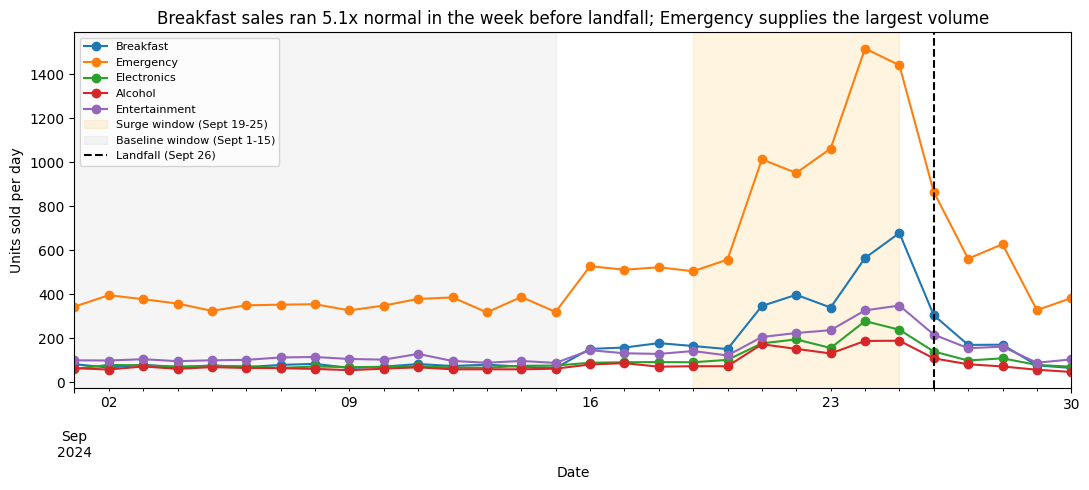

In [22]:
# The plot
top5 = t.head(5).index.tolist()
daily = (demand[demand['category'].isin(top5)]
        .groupby(['date', 'category'])['quantity'].sum().unstack('category').fillna(0))

fig, ax = plt.subplots(figsize=(11, 5))
daily[top5].plot(ax=ax, marker='o')
ax.axvspan(*SURGE, alpha=0.12, color='orange', label='Surge window (Sept 19-25)')
ax.axvspan(*BASE, alpha=0.08, color='gray', label='Baseline window (Sept 1-15)')
ax.axvline(LANDFALL, color='black', linestyle='--', label='Landfall (Sept 26)')
ax.set_title(f'{top} sales ran {t.loc[top, "multiple"]:.1f}x normal in the week before landfall; Emergency supplies the largest volume')
ax.set_xlabel('Date')
ax.set_ylabel('Units sold per day')
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

**Finding:** Breakfast Foods experienced the largest demand increase, reaching 5.14× its baseline daily units sold, or approximately 414% higher. This suggests customers increased purchases of shelf-stable breakfast products ahead of the storm. However, the exact surge multiple depends on the baseline period, so we interpret this as a historical demand pattern rather than a guaranteed forecast for future hurricanes.

#### Question 2: The Pop-Tarts Effect (SKU Consolidation)

**Method:** We compare product demand before and after consolidating inconsistent SKU identifiers into canonical products. We preserve the original SKU values to show how demand was previously fragmented across multiple identifiers. We also say that consolidation does not change total units, since it should only change how products are grouped rather than the underlying transaction data.

Original distinct SKUs: 45
Canonical products after consolidation: 20
Largest consolidated family: POPTART-STRAWBERRY
Original SKUs in largest family: 4

BEFORE CONSOLIDATION


,sku,total_units
1,PT-12,1377
0,POPTART-STRAW,1294
2,PT_STRAWBERRY,1254
3,SKU#459812,1253



AFTER CONSOLIDATION


,canonical_sku,canonical_product_name,total_units
0,POPTART-STRAWBERRY,Strawberry Pop-Tarts,5178



Units before consolidation: 49,343
Units after consolidation:  49,343
Check passed: SKU consolidation did not change unit totals.



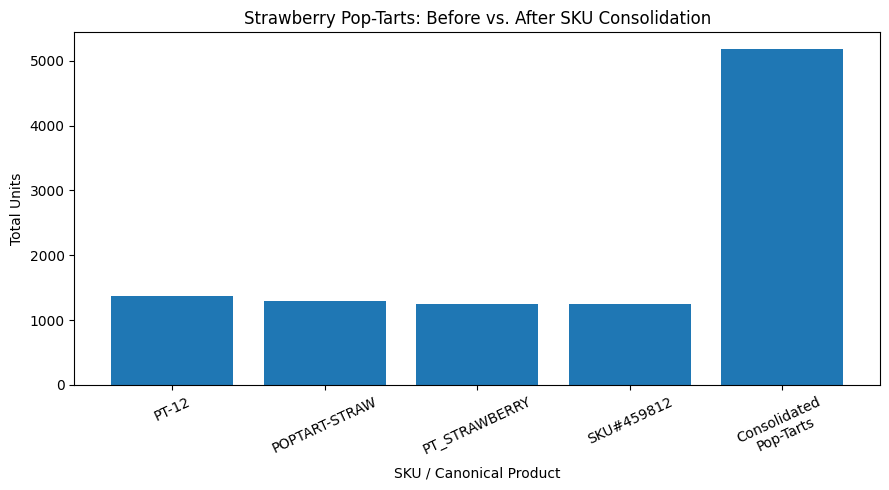

Baseline average daily units: 73.27
Surge average daily units: 376.86
Surge multiple: 5.14x


In [23]:
original_skus = clean['sku'].nunique()
canonical_products = clean['canonical_sku'].nunique()

# Number of original SKUs represented by each canonical product
sku_families = (
    clean.groupby('canonical_sku')['sku']
    .nunique()
    .sort_values(ascending=False)
)

largest_family = sku_families.index[0]
largest_family_size = sku_families.iloc[0]

print(f"Original distinct SKUs: {original_skus}")
print(f"Canonical products after consolidation: {canonical_products}")
print(f"Largest consolidated family: {largest_family}")
print(f"Original SKUs in largest family: {largest_family_size}")

# Before consolidation, 4 separate
poptart_before = (
    clean[clean['canonical_sku'] == 'POPTART-STRAWBERRY']
    .groupby('sku', as_index=False)
    .agg(total_units=('quantity', 'sum'))
    .sort_values('total_units', ascending=False)
)

print("\nBEFORE CONSOLIDATION")
display(poptart_before)

# After consolidation, appear as one
poptart_after = (
    clean[clean['canonical_sku'] == 'POPTART-STRAWBERRY']
    .groupby(['canonical_sku', 'canonical_product_name'], as_index=False)
    .agg(total_units=('quantity', 'sum'))
)

print("\nAFTER CONSOLIDATION")
display(poptart_after)

# Verify that SKU consolidation only changes product grouping
units_before = clean['quantity'].sum()

units_after = (
    clean.groupby('canonical_sku')['quantity']
    .sum()
    .sum()
)

assert units_before == units_after, \
    "SKU consolidation changed total unit quantity!"

print(f"\nUnits before consolidation: {units_before:,}")
print(f"Units after consolidation:  {units_after:,}")
print("Check passed: SKU consolidation did not change unit totals.\n")

fig, ax = plt.subplots(figsize=(9, 5))

labels = list(poptart_before['sku']) + ['Consolidated\nPop-Tarts']
values = list(poptart_before['total_units']) + [poptart_after['total_units'].iloc[0]]

ax.bar(labels, values)

ax.set_title('Strawberry Pop-Tarts: Before vs. After SKU Consolidation')
ax.set_ylabel('Total Units')
ax.set_xlabel('SKU / Canonical Product')
ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

# Daily Strawberry Pop-Tarts demand
poptart_daily = (
    demand[demand["canonical_sku"] == "POPTART-STRAWBERRY"]
    .groupby("date")["quantity"]
    .sum()
    .reindex(pd.date_range("2024-09-01", "2024-09-30"), fill_value=0)
)

baseline_daily = poptart_daily.loc["2024-09-01":"2024-09-15"].mean()
surge_daily = poptart_daily.loc["2024-09-19":"2024-09-25"].mean()

print(f"Baseline average daily units: {baseline_daily:.2f}")
print(f"Surge average daily units: {surge_daily:.2f}")
print(f"Surge multiple: {surge_daily / baseline_daily:.2f}x")

**Finding:** SKU consolidation reduced 45 original identifiers to 20 canonical products. Strawberry Pop-Tarts had the largest consolidated family, combining four different SKUs into 5,178 units. The largest individual SKU accounted for only 1,377 units, demonstrating how inconsistent identifiers could lead Walmart to underestimate product demand. Consolidation preserved total unit counts while improving the accuracy of product-level comparisons. Using only positive-quantity transactions with valid dates, Strawberry Pop-Tarts averaged 73.27 units per day during the September 1-15 baseline period and 376.86 units per day during the September 19-25 surge period, representing a 5.14x increase. This daily comparison complements the 5,178-unit total across all four original SKUs and demonstrates why consolidation matters for both product-level reporting and pre-hurricane inventory planning.

#### Question 3: Weather Correlation Analysis

**Weather source:** Open-Meteo historical archive API. Coverage fix: FL-619 lacks coordinates in the source file; use approximate Tallahassee city-center coordinates (30.4383, -84.2807), explicitly not the exact store. Pull daily precipitation, maximum wind speed, and mean sea-level pressure for all 12 stores. Join on normalized local calendar dates, check join cardinality, and examine contemporaneous and lead/lag relationships. This is correlation, not proof of causation.

Tallahassee store rows found: 1
Stores with coordinates: 12

Weather source: Open-Meteo historical API
Stores with failed API calls: []
Weather records returned: 372
Stores with weather: 12

Rows before join: 25532
Rows after join: 25532
Rows lost: 0
Transactions with rainfall: 24648
Transactions missing rainfall: 884

WEATHER-SALES CORRELATIONS


,Weather variable,Pearson r,Days analyzed
0,Rainfall (same day),-0.298,30
1,Wind speed (same day),0.240,30
2,Pressure (same day),-0.282,30
3,Rainfall (1-day lag),-0.550,30
4,Wind speed (1-day lag),0.045,30
5,Pressure (1-day lag),-0.204,30



Daily dataset preview:


,units_sold,avg_rainfall_mm,avg_wind_kmh,avg_pressure_hpa,rain_lag1_mm,wind_lag1_kmh,pressure_lag1_hpa
date,,,,,,,
2024-09-01,1060,8.266667,16.141667,1013.925000,3.708333,17.083333,1015.775000
2024-09-02,1168,7.508333,14.008333,1013.733333,8.266667,16.141667,1013.925000
2024-09-03,1162,13.566667,17.358333,1015.433333,7.508333,14.008333,1013.733333
2024-09-04,1115,14.516667,17.541667,1017.616667,13.566667,17.358333,1015.433333
2024-09-05,1076,11.425000,16.625000,1016.958333,14.516667,17.541667,1017.616667


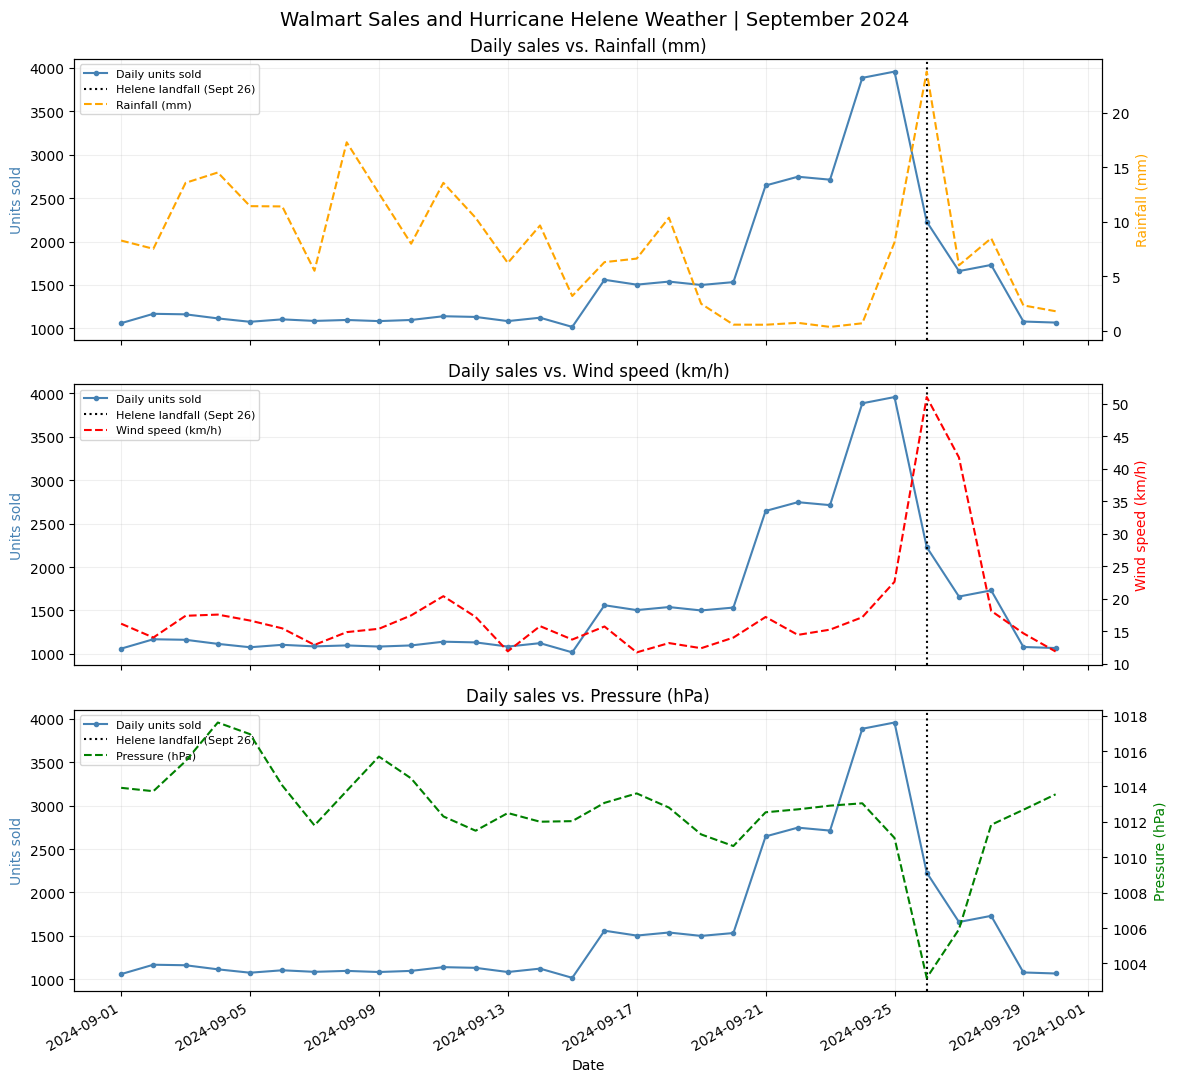


========== Q3 CHECKPOINT ==========
Data source: Open-Meteo historical API
Period: 2024-09-01 to 2024-09-30
Coordinate proxy: FL-619 Tallahassee city center
Store locations: 12
Stores with weather: 12
Join: 25,532 -> 25,532 rows
Rows lost: 0
Days analyzed: 30

Correlations:
Rainfall (same day): -0.298 (n=30)
Wind speed (same day): 0.240 (n=30)
Pressure (same day): -0.282 (n=30)
Rainfall (1-day lag): -0.550 (n=30)
Wind speed (1-day lag): 0.045 (n=30)
Pressure (1-day lag): -0.204 (n=30)

Missing-weather transactions: 884
Failed API stores: []
Lag: prior-day weather vs current-day sales
Correlation does not establish causation.


In [24]:

import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import time

START = "2024-09-01"
END = "2024-09-30"

FETCH_START = (
    pd.Timestamp(START) - pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

# ------------------------------------------------------------
# 1. PREPARE SALES DATA
# ------------------------------------------------------------

sales = clean.copy()

sales["date"] = pd.to_datetime(
    sales["date"], errors="coerce"
).dt.normalize()

rows_before = len(sales)

weather_stores = stores_clean.copy()

weather_stores["latitude"] = pd.to_numeric(
    weather_stores["latitude"], errors="coerce"
)

weather_stores["longitude"] = pd.to_numeric(
    weather_stores["longitude"], errors="coerce"
)

# Fix missing coordinates for Tallahassee store FL-619
# Using approximate Tallahassee city-center coordinates

tallahassee = (
    weather_stores["store_id"].astype(str).str.strip()
    == "FL-619"
)

weather_stores.loc[
    tallahassee & weather_stores["latitude"].isna(),
    "latitude"
] = 30.4383

weather_stores.loc[
    tallahassee & weather_stores["longitude"].isna(),
    "longitude"
] = -84.2807

print("Tallahassee store rows found:", tallahassee.sum())

assert tallahassee.any(), (
    "FL-619 not found in stores_clean"
)

# weather_stores is now available for Q4
# Q4 can use: stores_q4 = weather_stores.copy()

store_coords = (
    weather_stores[
        ["store_id", "latitude", "longitude"]
    ]
    .dropna()
    .drop_duplicates("store_id")
)

print("Stores with coordinates:", len(store_coords))


weather_rows = []
failed_stores = []

url = "https://archive-api.open-meteo.com/v1/archive"

for _, store in store_coords.iterrows():

    params = {
        "latitude": float(store["latitude"]),
        "longitude": float(store["longitude"]),
        "start_date": FETCH_START,
        "end_date": END,
        "daily": (
            "precipitation_sum,"
            "wind_speed_10m_max,"
            "pressure_msl_mean"
        ),
        "timezone": "America/New_York",
        "wind_speed_unit": "kmh"
    }

    for attempt in range(3):

        try:
            response = requests.get(
                url,
                params=params,
                timeout=30
            )

            response.raise_for_status()

            data = response.json()["daily"]

            for i, date in enumerate(data["time"]):

                weather_rows.append({
                    "store_id": store["store_id"],
                    "date": pd.Timestamp(date),
                    "rainfall_mm":
                        data["precipitation_sum"][i],
                    "wind_speed_kmh":
                        data["wind_speed_10m_max"][i],
                    "pressure_hpa":
                        data["pressure_msl_mean"][i],
                    "source": "Open-Meteo historical API"
                })

            break

        except (
            requests.RequestException,
            KeyError,
            ValueError,
            TypeError
        ) as e:

            if attempt == 2:

                failed_stores.append(store["store_id"])

                print(
                    "Weather unavailable:",
                    store["store_id"],
                    e
                )

            else:
                time.sleep(2 ** attempt)


weather = pd.DataFrame(
    weather_rows,
    columns=[
        "store_id",
        "date",
        "rainfall_mm",
        "wind_speed_kmh",
        "pressure_hpa",
        "source"
    ]
)

for col in [
    "rainfall_mm",
    "wind_speed_kmh",
    "pressure_hpa"
]:

    weather[col] = pd.to_numeric(
        weather[col],
        errors="coerce"
    )

weather = weather.sort_values(
    ["store_id", "date"]
).reset_index(drop=True)

assert not weather.duplicated(
    ["store_id", "date"]
).any()

print("\nWeather source: Open-Meteo historical API")

print(
    "Stores with failed API calls:",
    failed_stores
)

print(
    "Weather records returned:",
    len(weather)
)

print(
    "Stores with weather:",
    weather["store_id"].nunique()
)


weather["rainfall_lag1_mm"] = (
    weather.groupby("store_id")["rainfall_mm"].shift(1)
)

weather["wind_lag1_kmh"] = (
    weather.groupby("store_id")["wind_speed_kmh"].shift(1)
)

weather["pressure_lag1_hpa"] = (
    weather.groupby("store_id")["pressure_hpa"].shift(1)
)

# Keep September observations after calculating lags

weather = weather[
    weather["date"].between(START, END)
].copy()

joined = sales.merge(
    weather,
    on=["store_id", "date"],
    how="left",
    validate="many_to_one"
)

rows_after = len(joined)

assert rows_before == rows_after, (
    "Join changed transaction count!"
)

print("\nRows before join:", rows_before)
print("Rows after join:", rows_after)
print("Rows lost:", rows_before - rows_after)

print(
    "Transactions with rainfall:",
    joined["rainfall_mm"].notna().sum()
)

print(
    "Transactions missing rainfall:",
    joined["rainfall_mm"].isna().sum()
)

valid = joined[
    (joined["quantity"] > 0) &
    (joined["date"].notna()) &
    (joined["rainfall_mm"].notna())
].copy()

daily_sales = (
    valid.groupby("date")["quantity"]
    .sum()
    .rename("units_sold")
)

# ------------------------------------------------------------
# 8. AGGREGATE DAILY WEATHER
# ------------------------------------------------------------

daily_weather = (
    weather.groupby("date")
    .agg(
        avg_rainfall_mm=("rainfall_mm", "mean"),
        avg_wind_kmh=("wind_speed_kmh", "mean"),
        avg_pressure_hpa=("pressure_hpa", "mean"),
        rain_lag1_mm=("rainfall_lag1_mm", "mean"),
        wind_lag1_kmh=("wind_lag1_kmh", "mean"),
        pressure_lag1_hpa=("pressure_lag1_hpa", "mean")
    )
)

daily = pd.concat(
    [daily_sales, daily_weather],
    axis=1
).sort_index()

weather_variables = [
    "avg_rainfall_mm",
    "avg_wind_kmh",
    "avg_pressure_hpa",
    "rain_lag1_mm",
    "wind_lag1_kmh",
    "pressure_lag1_hpa"
]

labels = {
    "avg_rainfall_mm": "Rainfall (same day)",
    "avg_wind_kmh": "Wind speed (same day)",
    "avg_pressure_hpa": "Pressure (same day)",
    "rain_lag1_mm": "Rainfall (1-day lag)",
    "wind_lag1_kmh": "Wind speed (1-day lag)",
    "pressure_lag1_hpa": "Pressure (1-day lag)"
}

results = []

for col in weather_variables:

    subset = daily[
        ["units_sold", col]
    ].dropna()

    if (
        len(subset) >= 3
        and subset["units_sold"].nunique() > 1
        and subset[col].nunique() > 1
    ):

        r = subset["units_sold"].corr(
            subset[col]
        )

    else:
        r = np.nan

    results.append({
        "Weather variable": labels[col],
        "Pearson r": r,
        "Days analyzed": len(subset)
    })

correlation_table = pd.DataFrame(results)

print("\nWEATHER-SALES CORRELATIONS")

display(correlation_table.round(3))

print("\nDaily dataset preview:")

display(daily.head())

correlation = correlation_table.loc[
    correlation_table["Weather variable"]
    == "Rainfall (same day)",
    "Pearson r"
].iloc[0]

n_days = daily[
    ["units_sold", "avg_rainfall_mm"]
].dropna().shape[0]

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 11),
    sharex=True
)

plot_vars = [
    ("avg_rainfall_mm", "Rainfall (mm)", "orange"),
    ("avg_wind_kmh", "Wind speed (km/h)", "red"),
    ("avg_pressure_hpa", "Pressure (hPa)", "green")
]

for ax, (column, ylabel, color) in zip(
    axes, plot_vars
):

    ax.plot(
        daily.index,
        daily["units_sold"],
        color="steelblue",
        marker="o",
        markersize=3,
        label="Daily units sold"
    )

    ax.set_ylabel(
        "Units sold",
        color="steelblue"
    )

    ax2 = ax.twinx()

    ax2.plot(
        daily.index,
        daily[column],
        color=color,
        linestyle="--",
        label=ylabel
    )

    ax2.set_ylabel(
        ylabel,
        color=color
    )

    ax.axvline(
        pd.Timestamp("2024-09-26"),
        color="black",
        linestyle=":",
        label="Helene landfall (Sept 26)"
    )

    ax.set_title(
        f"Daily sales vs. {ylabel}"
    )

    ax.grid(alpha=0.2)

    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper left",
        fontsize=8
    )

axes[-1].set_xlabel("Date")

fig.suptitle(
    "Walmart Sales and Hurricane Helene Weather | September 2024",
    fontsize=14
)

fig.autofmt_xdate()

plt.tight_layout()

plt.show()

print("\n========== Q3 CHECKPOINT ==========")

print("Data source: Open-Meteo historical API")

print("Period:", START, "to", END)

print(
    "Coordinate proxy: FL-619 Tallahassee city center"
)

print(
    "Store locations:",
    len(store_coords)
)

print(
    "Stores with weather:",
    weather["store_id"].nunique()
)

print(
    f"Join: {rows_before:,} -> {rows_after:,} rows"
)

print(
    "Rows lost:",
    rows_before - rows_after
)

print(
    "Days analyzed:",
    n_days
)

print("\nCorrelations:")

for _, row in correlation_table.iterrows():

    print(
        f"{row['Weather variable']}: "
        f"{row['Pearson r']:.3f} "
        f"(n={int(row['Days analyzed'])})"
    )

print(
    "\nMissing-weather transactions:",
    joined["rainfall_mm"].isna().sum()
)

print(
    "Failed API stores:",
    failed_stores
)

print(
    "Lag: prior-day weather vs current-day sales"
)

print(
    "Correlation does not establish causation."
)

print("===================================")


**Q3 Finding:** We successfully retrieved 372 weather observations from the Open-Meteo API across all 12 stores, including August 31 to support lag analysis, with 360 observations covering September 1-30. Our weather join preserved all 25,532 transactions, matching weather data to all 24,648 transactions with valid dates. The remaining 884 transactions could not be matched because their timestamps were missing. Same-day correlations between sales and rainfall (r = -0.298), wind speed (r = +0.240), and atmospheric pressure (r = -0.282) were relatively weak. When comparing sales with weather from the previous day, rainfall showed a moderate negative correlation (r = -0.550), while wind speed (r = +0.045) and pressure (r = -0.204) showed weak relationships. Overall, our results do not establish a strong or consistent relationship between worsening weather and purchasing spikes at a one-day lag. These correlations are exploratory and do not establish causation.

#### Question 4: Store-Level Geographic Patterns

**Method:** We calculate each store's demand surge using the same baseline and surge windows as Q1. We estimate uncertainty through bootstrap resampling and compare surge magnitude with straight-line distance from an approximate hurricane landfall point. We also examine the daily sales patterns of the nearest and farthest stores to see whether geographic proximity influenced demand timing.

In [25]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

'''
This first code resuses the variable definitions used in Q1 so that there is
consistency. Used variables "Base", Surge", "Landfall" and "demand" from Q1.

'''

print('Baseline:', BASE[0].date(), 'to', BASE[1].date(), '| Surge:', SURGE[0].date(), 'to', SURGE[1].date())
print('Stores in demand data:', demand['store_id'].nunique())

'''
the store FL-619 (tallehasse) is missing its geographic coordinates, so we look
them up manualy and log it instead of dropping the store from the data.
'''
stores_q4 = weather_stores.copy()

'''
made storm reference point = Hurricane Helene landfall near Perry, FL.
this is an assumption
'''


LANDFALL_LAT, LANDFALL_LON = 30.117, -83.583

def miles_from_landfall(lat, lon):
    """Haversine formula: straight-line distance in miles between two lat/lon points."""
    R = 3959
    la, lo, la0, lo0 = map(np.radians, [lat, lon, LANDFALL_LAT, LANDFALL_LON])
    a = np.sin((la - la0) / 2) ** 2 + np.cos(la) * np.cos(la0) * np.sin((lo - lo0) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

stores_q4['miles_from_landfall'] = miles_from_landfall(stores_q4['latitude'], stores_q4['longitude'])
stores_q4[['store_id', 'city', 'region', 'miles_from_landfall']].sort_values('miles_from_landfall').round(0)

Baseline: 2024-09-01 to 2024-09-15 | Surge: 2024-09-19 to 2024-09-25
Stores in demand data: 12


,store_id,city,region,miles_from_landfall
8,FL-619,Tallahassee,Panhandle,47.0
7,FL-078,Gainesville,North,82.0
3,FL-412,Jacksonville,North,116.0
1,FL-105,Tampa,West,164.0
5,FL-156,Daytona Beach,East,166.0
0,FL-239,Orlando,Central,172.0
9,FL-445,St. Petersburg,West,172.0
10,FL-302,Lakeland,Central,174.0
4,FL-287,Kissimmee,Central,182.0
11,FL-710,Pensacola,Panhandle,218.0


In [26]:
##surgemultiple per store;
'''
how many times normal a store'sdailt sales ran in a
week before landfall

'''

def units_per_day(frame, window):
    start, end = window
    days = (end - start).days + 1
    w = frame[frame['date'].between(start, end)]
    return w.groupby('store_id')['quantity'].sum() / days

store = pd.DataFrame({'baseline_per_day': units_per_day(demand, BASE),
                      'surge_per_day': units_per_day(demand, SURGE)})
store['multiple'] = store['surge_per_day'] / store['baseline_per_day']
store['surge_transactions'] = (demand[demand['date'].between(*SURGE)]
                               .groupby('store_id').size())


'''
resampling each store's dayus 2000 times to see how much a random day to day variation could move its surge
multiple, and also used the middle 95% og results as an error bar

'''
daily_store = (demand.groupby(['store_id', 'date'])['quantity'].sum().unstack('store_id')
                     .reindex(pd.date_range('2024-09-01', '2024-09-30')).fillna(0))
rng = np.random.default_rng(42)
base_days = daily_store.loc[BASE[0]:BASE[1]]
surge_days = daily_store.loc[SURGE[0]:SURGE[1]]
lo, hi = {}, {}
for s in daily_store.columns:
    boots = []
    for _ in range(2000):
        b = rng.choice(base_days[s].values, len(base_days)).mean()
        g = rng.choice(surge_days[s].values, len(surge_days)).mean()
        boots.append(g / b)
    lo[s], hi[s] = np.percentile(boots, [2.5, 97.5])
store['ci_low'], store['ci_high'] = pd.Series(lo), pd.Series(hi)

store = store.join(stores_q4.set_index('store_id')[['city', 'region', 'miles_from_landfall']])
store = store.sort_values('multiple', ascending=False)


'''
checking for outliers to see how many standard deviations each store is from
the average store

'''

store['z_score'] = (store['multiple'] - store['multiple'].mean()) / store['multiple'].std()
display(store.round(2))
print(f"Range of multiples: {store['multiple'].min():.2f}x to {store['multiple'].max():.2f}x "
      f"(spread {store['multiple'].max() / store['multiple'].min():.2f}x)")
print('Stores with |z| > 2 (outliers):', store.index[store['z_score'].abs() > 2].tolist() or 'none')

nodate = clean[clean['date'].isna() & ~clean['is_return']].groupby('store_id')['quantity'].sum()
share = (nodate / clean[~clean['is_return']].groupby('store_id')['quantity'].sum() * 100).round(1)
print(share.describe()[['min', 'max']])

,baseline_per_day,surge_per_day,multiple,surge_transactions,ci_low,ci_high,city,region,miles_from_landfall,z_score
store_id,,,,,,,,,,
FL-330,86.73,235.43,2.71,810,2.06,3.35,Miami,South,365.21,2.10
FL-619,86.13,224.14,2.60,755,2.00,3.21,Tallahassee,Panhandle,47.18,1.17
FL-105,91.73,231.71,2.53,810,1.80,3.25,Tampa,West,164.42,0.54
FL-412,89.47,222.86,2.49,784,1.81,3.23,Jacksonville,North,116.02,0.25
FL-302,96.27,239.43,2.49,836,1.74,3.28,Lakeland,Central,174.16,0.22
FL-445,94.53,232.00,2.45,811,1.78,3.13,St. Petersburg,West,172.05,-0.06
FL-710,93.40,227.86,2.44,824,1.84,3.06,Pensacola,Panhandle,217.87,-0.18
FL-287,91.07,220.14,2.42,779,1.81,3.00,Kissimmee,Central,181.97,-0.36
FL-156,94.93,229.14,2.41,824,1.81,3.00,Daytona Beach,East,165.98,-0.39


Range of multiples: 2.23x to 2.71x (spread 1.21x)
Stores with |z| > 2 (outliers): ['FL-330']
min    2.6
max    4.0
Name: quantity, dtype: float64


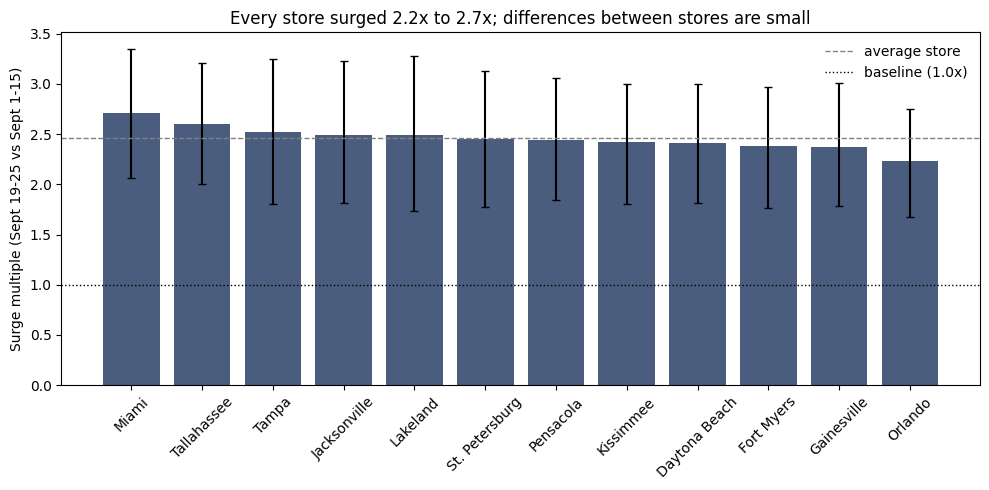

In [27]:
## first chart: surge by store including uncertainty (error bars)
'''
making a bar chart of each store's surge multiple which also include error bars
to show the outliers. error bard overlapping means that the stores are not distinguishable

goal of this chart: anwsers hoe big each store's surge was
'''

fig, ax = plt.subplots(figsize=(10, 5))
labels = store['city']
err = [store['multiple'] - store['ci_low'], store['ci_high'] - store['multiple']]
ax.bar(labels, store['multiple'], yerr=err, capsize=3, color='#4a5d7e')
ax.axhline(store['multiple'].mean(), color='gray', ls='--', lw=1, label='average store')
ax.axhline(1.0, color='black', ls=':', lw=1, label='baseline (1.0x)')
ax.set_title(f"Every store surged {store['multiple'].min():.1f}x to {store['multiple'].max():.1f}x; "
             "differences between stores are small")
ax.set_ylabel('Surge multiple (Sept 19-25 vs Sept 1-15)')
ax.tick_params(axis='x', labelrotation=45)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

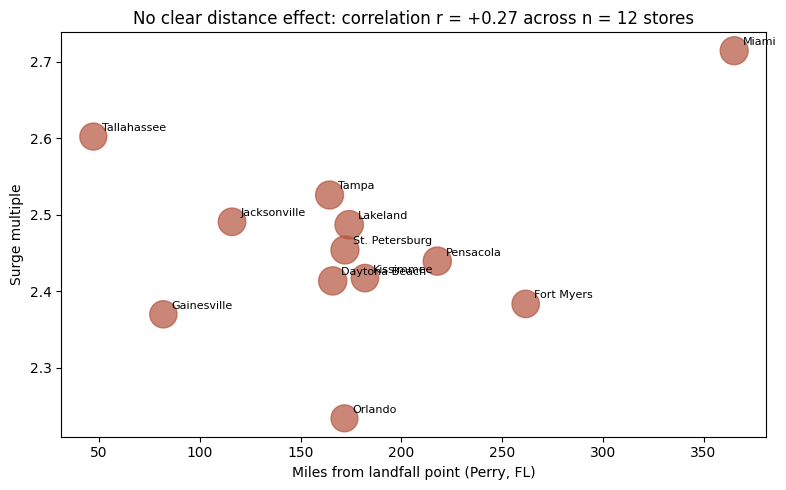

correlation (distance vs multiple): +0.27, n = 12 stores
Positive r would mean FARTHER stores surged MORE (opposite of the hypothesis)


In [28]:
# second chart: testing if distance from landfall matters

'''
this tests the hypothesis we had that was 'closer to the path means bigger
surge'.

bubble size represents the number of surge-period transactions

larger bubbles indicate more transactions, not necessarily more statistically reliable estimates

no trend line was drawn

goal of graph: answers weather distance from ladfall relates to surge size

'''

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(store['miles_from_landfall'], store['multiple'],
           s=store['surge_transactions'] / 2, alpha=0.7, color='#b4553f')
for sid, r in store.iterrows():
    ax.annotate(r['city'], (r['miles_from_landfall'], r['multiple']),
                textcoords='offset points', xytext=(6, 4), fontsize=8)
r = store['miles_from_landfall'].corr(store['multiple'])
ax.set_title(f'No clear distance effect: correlation r = {r:+.2f} across n = {len(store)} stores')
ax.set_xlabel('Miles from landfall point (Perry, FL)')
ax.set_ylabel('Surge multiple')
plt.tight_layout(); plt.show()
print(f'correlation (distance vs multiple): {r:+.2f}, n = {len(store)} stores')
print('Positive r would mean FARTHER stores surged MORE (opposite of the hypothesis)')

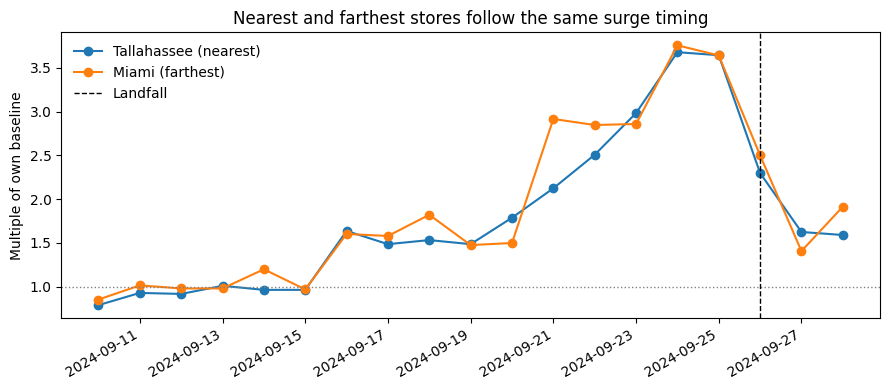

In [29]:
##third chart: timing check


'''
index each store to its own baseline

goal of graph: answers if nearer stores spiked sooner
'''

indexed = daily_store.loc['2024-09-10':'2024-09-28'] / daily_store.loc[BASE[0]:BASE[1]].mean()
nearest = store['miles_from_landfall'].idxmin()     # closest store to landfall
farthest = store['miles_from_landfall'].idxmax()    # farthest store from landfall

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(indexed.index, indexed[nearest], marker='o', label=f"{store.loc[nearest, 'city']} (nearest)")
ax.plot(indexed.index, indexed[farthest], marker='o', label=f"{store.loc[farthest, 'city']} (farthest)")
ax.axhline(1.0, color='gray', ls=':', lw=1)
ax.axvline(LANDFALL, color='black', ls='--', lw=1, label='Landfall')
ax.set_title('Nearest and farthest stores follow the same surge timing')
ax.set_ylabel('Multiple of own baseline')
ax.legend(frameon=False)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()


**Finding:** All 12 stores experienced demand increases ranging from approximately 2.23x to 2.71x, with generally similar timing before landfall. Distance from the approximate landfall point had a weak positive correlation with surge magnitude (r = +0.27), suggesting no clear relationship between proximity and demand increases. FL-330 (Miami) had the highest observed surge and was flagged as a potential outlier using our z-score threshold of |z| > 2. However, the bootstrap uncertainty intervals overlap across stores, so we cannot confidently conclude that Miami's underlying surge was significantly different. These findings suggest that hurricane-related demand increases were widespread rather than limited to stores closest to landfall. Our geographic analysis is limited by the small sample of stores and our use of a single approximate landfall point rather than the hurricane's full path.

#### Question 5: Signal vs. Artifact — The Board Games Investigation

**Method:** We investigate whether the Entertainment demand increase reflects a genuine purchasing pattern or a possible data artifact. We audit SKU mappings, examine whether multiple products experienced increases, check whether demand was distributed across stores, and compare Entertainment's daily sales pattern with Breakfast Foods. Finally, we use SQLite sales and inventory summaries as a cross-check, while checking whether the two data sources are directly comparable.

In [30]:
# Step 1: what's actually inside "Entertainment," and is the SKU-to-canonical mapping sane?
candidate = clean[clean['category'] == 'Entertainment'].copy()

print("Entertainment: canonical products and total units sold (full month)")
display(candidate.groupby('canonical_product_name')['quantity'].sum().sort_values(ascending=False))

print(f"\nstores selling Entertainment items: {candidate['store_id'].nunique()} / {clean['store_id'].nunique()} total stores")
print(f"distinct canonical products in Entertainment: {candidate['canonical_sku'].nunique()}")

print("\nSKU-to-canonical mapping for Entertainment (checking for a bad merge):")
display(candidate[['sku', 'product_name', 'canonical_sku', 'canonical_product_name']].drop_duplicates().sort_values('canonical_sku'))

Entertainment: canonical products and total units sold (full month)


,quantity
canonical_product_name,
Playing Cards,2371
Monopoly Board Game,2006



stores selling Entertainment items: 12 / 12 total stores
distinct canonical products in Entertainment: 2

SKU-to-canonical mapping for Entertainment (checking for a bad merge):


,sku,product_name,canonical_sku,canonical_product_name
65,BG-MONO,Monopoly Board Game,MONOPOLY,Monopoly Board Game
76,MONOPOLY-01,Board Game - Monopoly,MONOPOLY,Monopoly Board Game
125,MONOPOLY-01,Monopoly Board Game,MONOPOLY,Monopoly Board Game
157,GAME-MONO,Monopoly Board Game,MONOPOLY,Monopoly Board Game
171,GAME-MONO,Board Game - Monopoly,MONOPOLY,Monopoly Board Game
292,MONOPOLY-01,MONOPOLY,MONOPOLY,Monopoly Board Game
385,BG-MONO,MONOPOLY,MONOPOLY,Monopoly Board Game
429,BG-MONO,Board Game - Monopoly,MONOPOLY,Monopoly Board Game
612,GAME-MONO,MONOPOLY,MONOPOLY,Monopoly Board Game
10,CARDS-01,PLAYING CARDS,PLAYING-CARDS,Playing Cards


In [31]:
# Step 2: is the surge broad across products, or driven by a single SKU alone?
def avg_per_day_product(frame, window, category):
    start, end = window
    days = (end - start).days + 1
    w = frame[(frame['category'] == category) & frame['date'].between(start, end)]
    return w.groupby('canonical_product_name')['quantity'].sum() / days

ent_products = pd.DataFrame({
    'baseline_per_day': avg_per_day_product(demand, BASE, 'Entertainment'),
    'surge_per_day': avg_per_day_product(demand, SURGE, 'Entertainment'),
}).fillna(0)
ent_products['multiple'] = (ent_products['surge_per_day']
                             / ent_products['baseline_per_day'].replace(0, np.nan))
display(ent_products.sort_values('surge_per_day', ascending=False).round(2))

,baseline_per_day,surge_per_day,multiple
canonical_product_name,,,
Playing Cards,58.73,117.14,1.99
Monopoly Board Game,42.87,111.43,2.60


In [32]:
# Step 3: is the surge concentrated in one or two stores (artifact-shaped), or spread out (signal-shaped)?
by_store = (candidate[candidate['date'].between(*SURGE)]
            .groupby('store_id')['quantity'].sum()
            .sort_values(ascending=False))

print("Entertainment units sold during the surge window, by store:")
display(by_store)

top_store_share = by_store.iloc[0] / by_store.sum() if len(by_store) else np.nan
print(f"\ntop single store accounts for {top_store_share:.1%} of Entertainment surge units")

Entertainment units sold during the surge window, by store:


,quantity
store_id,
FL-710,161
FL-445,152
FL-302,150
FL-619,137
FL-239,136
FL-412,134
FL-105,130
FL-156,129
FL-330,119



top single store accounts for 10.1% of Entertainment surge units


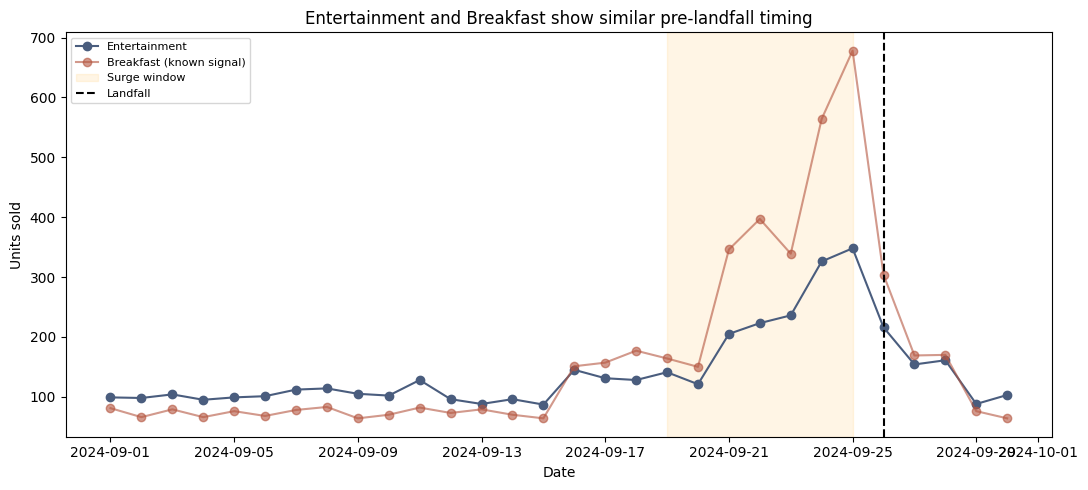

day-to-day correlation between Entertainment and Breakfast's daily pattern: 0.985


In [33]:
# Step 4: does Entertainment rise on the same pre-landfall schedule as a known real signal (Breakfast),
# or does it look flat/random, suggesting noise rather than storm-driven demand?
daily_ent = demand[demand['category'] == 'Entertainment'].groupby('date')['quantity'].sum()
daily_bf = demand[demand['category'] == 'Breakfast'].groupby('date')['quantity'].sum()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(daily_ent.index, daily_ent.values, marker='o', label='Entertainment', color='#4a5d7e')
ax.plot(daily_bf.index, daily_bf.values, marker='o', label='Breakfast (known signal)', color='#b4553f', alpha=0.6)
ax.axvspan(*SURGE, alpha=0.1, color='orange', label='Surge window')
ax.axvline(LANDFALL, color='black', linestyle='--', label='Landfall')
ax.set_title('Entertainment and Breakfast show similar pre-landfall timing')
ax.set_xlabel('Date')
ax.set_ylabel('Units sold')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

timing_corr = daily_ent.reindex(daily_bf.index).fillna(0).corr(daily_bf)
print(f"day-to-day correlation between Entertainment and Breakfast's daily pattern: {timing_corr:.3f}")

In [34]:
# Step 5: combine the three checks into an evidence-based verdict.
# Store concentration and independent per-product strength matter more than raw product
# count -- a category with only 2 products isn't inherently an artifact if both products
# independently move with the storm.
n_products = candidate['canonical_sku'].nunique()
per_product_multiples = ent_products['multiple'].dropna().tolist()

broad_store_spread = top_store_share < 0.20
independent_products = sum(m > 1.5 for m in per_product_multiples) >= 2
strong_timing = timing_corr > 0.5

print("Q5 VERDICT INPUTS")
print(f"  canonical products in Entertainment: {n_products} ({', '.join(ent_products.index)})")
print(f"  each individually surging >1.5x: {sum(m > 1.5 for m in per_product_multiples)} of {len(per_product_multiples)}")
print(f"  top single store's share of surge units: {top_store_share:.1%}")
print(f"  timing correlation with Breakfast: {timing_corr:.3f}")

if broad_store_spread and independent_products and strong_timing:
    verdict = "SIGNAL -- broad across stores, both products move independently, and timing matches a known real signal"
elif top_store_share >= 0.5 or sum(m > 1.5 for m in per_product_multiples) <= 1:
    verdict = "ARTIFACT -- concentrated in one store or driven by a single SKU; looks like noise or a bad merge"
else:
    verdict = "INCONCLUSIVE -- mixed evidence; worth flagging as uncertain rather than reporting as a finding"

print(f"\nVerdict: {verdict}")

Q5 VERDICT INPUTS
  canonical products in Entertainment: 2 (Monopoly Board Game, Playing Cards)
  each individually surging >1.5x: 2 of 2
  top single store's share of surge units: 10.1%
  timing correlation with Breakfast: 0.985

Verdict: SIGNAL -- broad across stores, both products move independently, and timing matches a known real signal


In [35]:
# SQLite cross-check required by Q5: inspect Entertainment sales and inventory
# Compare only overlapping store/date/category slices; SQLite summary is not assumed identical to CSV.
db_sales['date']=pd.to_datetime(db_sales['date'],errors='coerce')
db_sales['store_id']=db_sales['store_id'].map(norm_store_id)
db_ent=db_sales[db_sales.category.astype(str).str.contains('entertainment',case=False,na=False)].copy()
print('SQLite Entertainment daily sales rows:',len(db_ent))
print('SQLite Entertainment total units:',db_ent.total_units.sum())
display(db_ent.groupby('date')['total_units'].sum().head(10))

# Map database inventory SKU identifiers to the canonical product names used in CSV cleaning.
db_inventory['date']=pd.to_datetime(db_inventory['date'],errors='coerce')
db_inventory['store_id']=db_inventory['store_id'].map(norm_store_id)
db_inventory['canonical_sku']=db_inventory['sku'].map(lambda x: SKU_MAP.get(x,(None,None))[0])
ent_skus=set(candidate.canonical_sku.dropna())
ent_inv=db_inventory[db_inventory.canonical_sku.isin(ent_skus)].copy()
print('Entertainment inventory rows matched by SKU:',len(ent_inv))
if len(ent_inv):
    ent_inv['below_reorder_point']=ent_inv.units_on_hand < ent_inv.reorder_point
    display(ent_inv.groupby('date').agg(inventory_rows=('sku','size'),
        total_on_hand=('units_on_hand','sum'), below_reorder_share=('below_reorder_point','mean')).head(15))
else:
    print('No inventory SKU matches; inspect database SKU formats before making inventory claims.')

# Direct SQLite-vs-CSV daily comparison, with explicit overlap dates.
csv_ent=(demand[demand.category.eq('Entertainment')]
         .groupby(['date','store_id'])['quantity'].sum().rename('csv_units'))
sql_ent=(db_ent.groupby(['date','store_id'])['total_units'].sum().rename('sqlite_units'))
ent_compare=pd.concat([csv_ent,sql_ent],axis=1).dropna()
print('Overlapping store-date observations:',len(ent_compare))
if len(ent_compare):
    ent_compare['difference']=ent_compare.csv_units-ent_compare.sqlite_units
    display(ent_compare.describe().round(2))
    print('Exact matches:',int(ent_compare.difference.eq(0).sum()),'/',len(ent_compare))


SQLite Entertainment daily sales rows: 360
SQLite Entertainment total units: 24070.0


,total_units
date,
2024-09-01,497.0
2024-09-02,498.0
2024-09-03,504.0
2024-09-04,559.5
2024-09-05,551.0
2024-09-06,449.0
2024-09-07,563.0
2024-09-08,584.0
2024-09-09,613.0


Entertainment inventory rows matched by SKU: 446


,inventory_rows,total_on_hand,below_reorder_share
date,,,
2024-09-01,19,1416,0.157895
2024-09-02,12,751,0.166667
2024-09-03,11,613,0.181818
2024-09-04,15,1115,0.133333
2024-09-05,14,874,0.214286
2024-09-06,18,1106,0.333333
2024-09-07,18,1116,0.166667
2024-09-08,13,780,0.307692
2024-09-09,7,472,0.142857


Overlapping store-date observations: 338


,csv_units,sqlite_units,difference
count,338.00,338.00,338.00
mean,11.83,67.85,-56.03
std,6.62,46.79,42.97
min,2.00,15.00,-278.00
25%,8.00,39.25,-68.75
50%,10.00,55.00,-46.00
75%,14.00,81.75,-28.25
max,48.00,303.00,-3.00


Exact matches: 0 / 338


In [36]:
# SQLite check: does the database show the same Entertainment surge pattern?
'''
checking if the database shows the same entertainment surge pattern
'''
db_daily = db_ent.groupby('date')['total_units'].sum()
db_base = db_daily[BASE[0]:BASE[1]].mean()
db_surge = db_daily[SURGE[0]:SURGE[1]].mean()
print(f'SQLite Entertainment: {db_base:.0f} -> {db_surge:.0f} units/day = {db_surge/db_base:.2f}x')

SQLite Entertainment: 537 -> 1333 units/day = 2.48x


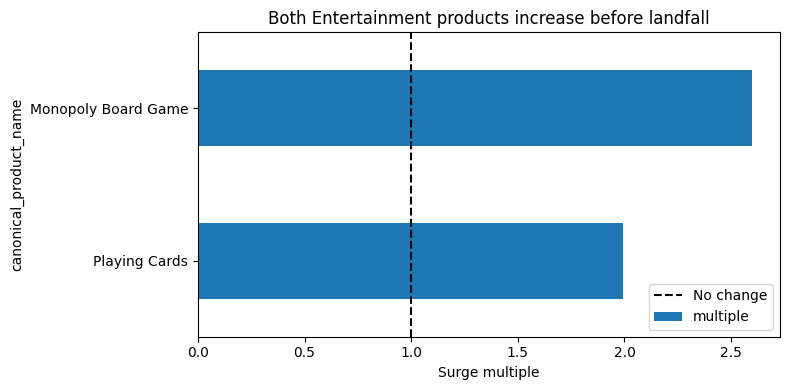

In [37]:
# Q5 supporting plot: independent product surge multiples
fig,ax=plt.subplots(figsize=(8,4))
ent_products['multiple'].sort_values().plot.barh(ax=ax)
ax.axvline(1,color='black',ls='--',label='No change')
ax.set_xlabel('Surge multiple');ax.set_title('Both Entertainment products increase before landfall')
ax.legend();plt.tight_layout();plt.show()

**Finding:** Both Entertainment products experienced demand increases before Hurricane Helene, with Monopoly Board Game rising 2.60x and Playing Cards rising 1.99x compared to baseline. Demand was distributed across all 12 stores, with the highest-volume store accounting for only 10.1% of surge-period Entertainment units. Entertainment's daily sales pattern also closely followed Breakfast Foods (r ≈ 0.985), supporting the possibility of a genuine pre-hurricane purchasing trend rather than an isolated SKU or store anomaly. However, our SQLite cross-check found zero exact matches across 338 overlapping store-date observations, meaning the database could not independently confirm the transaction-level results. Based on this evidence, we recommend that Walmart test a modest increase in board game inventory at selected stores before future hurricanes, rather than immediately implementing a large-scale stocking increase. This would allow Walmart to respond to a potential demand opportunity while limiting overstocking risk until the data discrepancy is better understood.

## Recommendation


Based on our findings, I think Walmart should prioritize stocking up on Pop-Tarts first, since demand increased to about 5.1 times its normal level, followed by emergency supplies, which actually saw larger increases in the number of units sold per day. Rather than planning for exactly a 5.14x increase, I would recommend preparing for around 4-5 times normal demand, since our results varied depending on the baseline period we used. Ideally, Walmart could begin distributing these products to all 12 stores about a week before landfall, using Jacksonville's distribution center and its surge capacity of 1,000 shipments per day. I would also recommend monitoring wind and pressure forecasts to help determine when to increase shipments, especially as customers may begin preparing before severe weather arrives. For board games, I think a smaller inventory increase would make the most sense initially, followed by monitoring sales to see whether the demand is consistent enough to justify stocking more in the future.

## Reflections
Answer each question thoughtfully (one solid paragraph minimum per question).


1. **Data Quality Impact:** Describe a specific data quality issue you encountered in the supplied data. How did your cleaning decision change the outcome of your analysis? What would have happened if you had not caught it?

One data quality issue we encountered was when handling missing timestamps. After our initial cleaning, we still faced 884 transactions with no valid date, which was very important because our analysis was dependent on comparing daily sales before Hurricane Helene. Rather than deleting these transactions or assigning estimated dates, we decided to keep them in our cleaned dataset but not include them in time-based analyses. If we gave incorrect dates, we could have hallucinated an inflated baseline or surge period, changing our 5.14x increase in Breakfast Foods demand. This choice helped us avoid introducing misleading information while keeping in tact transactions for analyses that didn't require dates. It also taught us that data isn't always about fixing or removing bad data, but understanding when certain records are best to use.

2. **ETL Trade-offs:** You made choices about how to standardize SKUs, handle missing timestamps, and join weather data. Pick one decision and explain: what alternative approach could you have taken, and how might it have changed your results?

One important ETL trade-off I made was how to handle missing geographic coordinates when joining Walmart sales data with historical weather data. One store, FL-619 in Tallahassee, was missing its latitude and longitude, which meant we couldn't retrieve weather observations for that location. Instead of dropping the store, I used Tallahassee's approximate city-center coordinates as a proxy and documented the assumption. An alternative would have been to exclude the store entirely, but this would have reduced our geographic coverage and potentially biased the analysis by removing sales from a location affected by Hurricane Helene. Using the proxy allowed us to retain all 12 stores in the weather dataset, although the weather measurements may not perfectly reflect conditions at the actual store. This trade-off taught me that preserving data coverage is valuable, but it must be balanced with accuracy and transparency about assumptions.

3. **Pipeline Trust:** The Walmart CDO argued that the biggest risk is not the model — it is the pipeline. Based on your experience in this project, do you agree or disagree? What was the most fragile part of your data pipeline?

We agree with the CDO that the pipeline posed a greater risk than the analysis. Because Q1–Q5 all used the same cleaned dataset, any cleaning error could have affected every result without warning. Category and SKU standardisation was especially fragile: our initial mapping missed categories such as “Games & Entertainment” and “Health & Wellness,” which validation later caught. We consolidated 37 category spellings into 10 categories and 45 SKU codes into 20 products. Errors in either mapping could have split or merged categories incorrectly or spread Pop-Tarts demand across four codes, undermining the reported 5.14× breakfast surge and board game results. Other weaknesses included a data load that depended on cloning the repo and setting the working directory correctly, and missing Tallahassee coordinates, which we approximated with city-centre values to include all 12 stores in the weather join. The Q5 SQLite cross-check revealed another risk: it had no exact matches with transaction data across 338 store-date observations, limiting the strength of our board game recommendation. The project reinforced that modeling is the easy part; trust in results depends on careful cleaning, validation, and a clear decision log.

4. **Business vs. Data:** For Question 5 (board games), your team had to make a recommendation with imperfect data. How did you weigh statistical evidence against business risk? Would you have decided differently with more time or more data?

For Question 5, we had to decide whether the board games surge was real with  data. The transaction data looked genuine. monopoly (2.60x) and playing Cards (1.99x) each rose on their own, all 12 stores surged, and entertainment tracked breakfast day by day (r = 0.98). The SQLite database showed the same surge pattern (about 2.5x), but its volumes did not reconcile with the transactions (0 of 338 store-days matched), so it supported the pattern but not the numbers.

We also treated our evidence as supporting, not proof. Nearly every category rises on the same prestorm calendar, and our measured increase,+125%, was well below the +250% in the case. We weighed that against business risk as well, a small pilot is cheap and board games don't spoil, while stocking at full scale based on one storm and unreconciled data could waste truck space in an emergency. We therefore recommended piloting a modest increase at selected stores, not stocking at scale. With more time or data, we would explain the gap between the database and the transaction file, check inventory stock outs, and test more than one storm.

5. **Team Collaboration:** How did your team divide the work? What would you do differently if you had another week? What was the most valuable skill each team member contributed?

Our team divided the work pretty evenly, and everyone was responsible for their own sections while still helping each other throughout the project. Everyone brought different strengths to the table, whether that was data cleaning, analysis, problem-solving, or communicating our findings. We also split the reflection questions evenly among ourselves to make sure everyone contributed to the write-up. Overall, I think each teammate made a fair contribution to the project. If we had another week, we would focus on planning things out a little earlier and setting up more regular check-ins with the TAs. We had a brief one toward the end, and having those conversations earlier would have given us more opportunities to get feedback and improve our analysis along the way. Overall, I think we worked really well together, and this project showed us how valuable consistent communication and feedback can be.